In [52]:
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.metrics import pairwise_distances

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)


In [53]:
df = pd.read_csv("ecommerce_dataset_clustering.csv")

In [54]:
if "dimensions" in df.columns:
    dimensions = df["dimensions"].astype(str).str.split("x", expand=True)
    if dimensions.shape[1] >= 3:
        df["Length"] = pd.to_numeric(dimensions[0], errors="coerce")
        df["Breadth"] = pd.to_numeric(dimensions[1], errors="coerce")
        df["Height"] = pd.to_numeric(dimensions[2], errors="coerce")
    df = df.drop(columns=["dimensions"])

id_like = []
for col in df.columns:
    normalized = col.lower().strip().replace(" ", "_")
    if normalized in {"product_id", "customer_id", "customerid", "id", "unnamed:_0"}:
        id_like.append(col)

for col in df.columns:
    if df[col].nunique(dropna=False) == len(df) and col not in id_like:
        if df[col].dtype == "object":
            id_like.append(col)

if id_like:
    df = df.drop(columns=id_like, errors="ignore")

print("Removed ID-like columns:", id_like)
print("Updated shape:", df.shape)
display(df.head())


Removed ID-like columns: ['product_id']
Updated shape: (1000, 7)


,price,category,brand,ratings,Length,Breadth,Height
0,124.84,Books,BrandC,4.1,10.04,3.32,4.85
1,93.09,Electronics,BrandC,4.3,18.61,8.78,3.74
2,132.38,Home,BrandE,5.0,4.99,5.82,6.13
3,176.15,Toys,BrandC,3.2,13.18,8.40,5.98
4,88.29,Home,BrandC,4.8,9.48,7.05,6.46


Numerical columns: ['price', 'ratings', 'Length', 'Breadth', 'Height']
Categorical columns: ['category', 'brand']


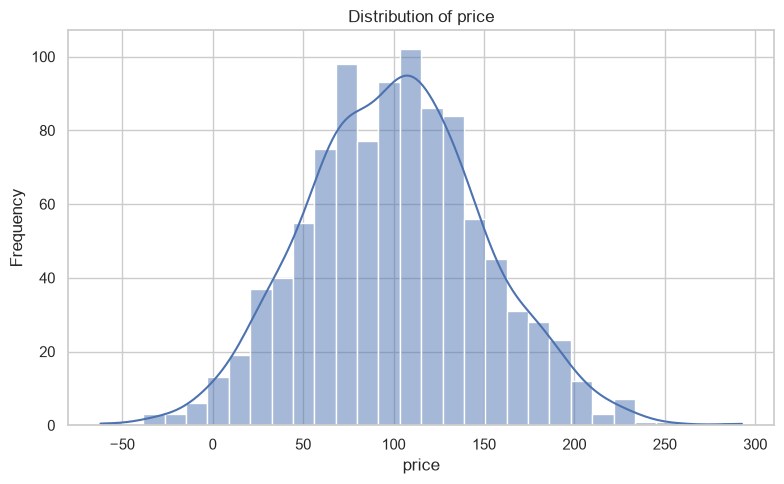

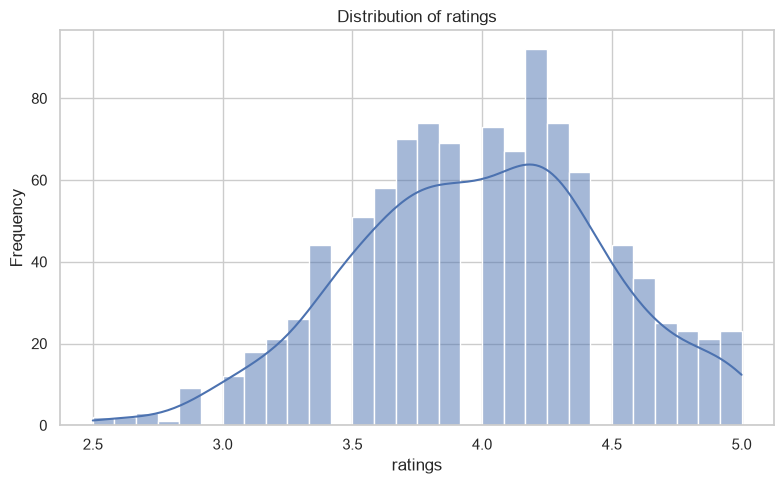

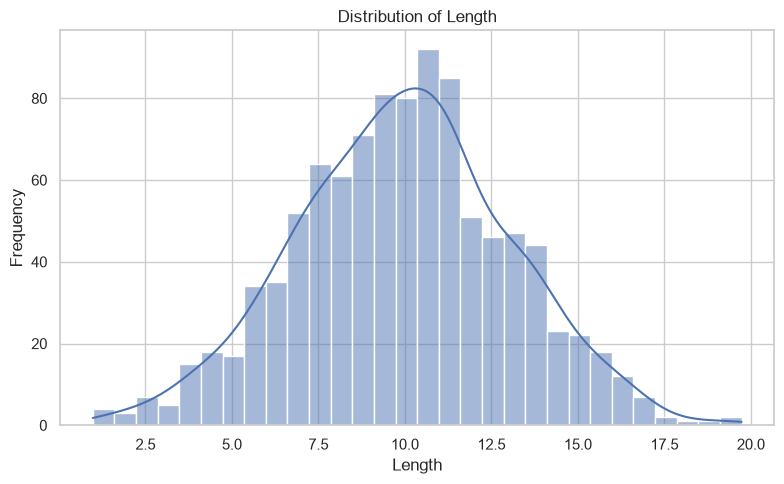

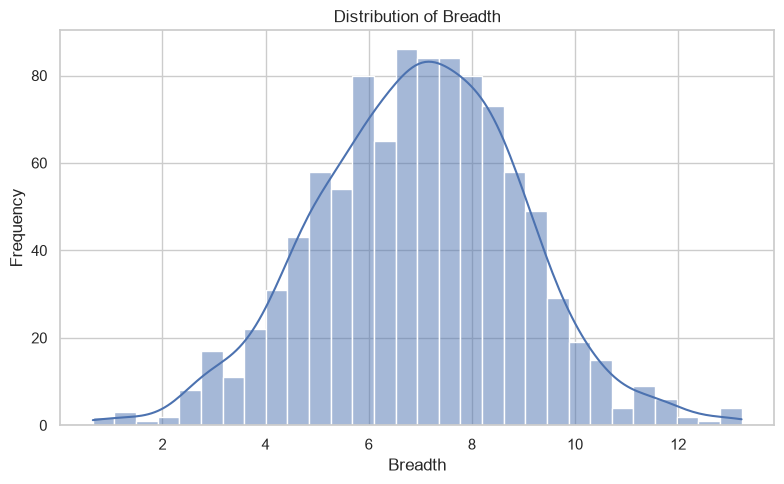

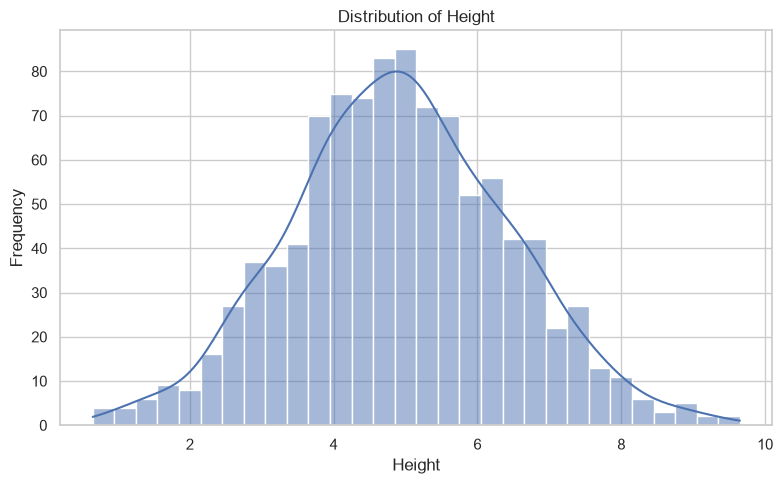

In [55]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical columns:", numeric_cols)
print("Categorical columns:", categorical_cols)

for col in numeric_cols:
    plt.figure(figsize=(8, 5))
    sns.histplot(df[col], kde=True, bins=30)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()


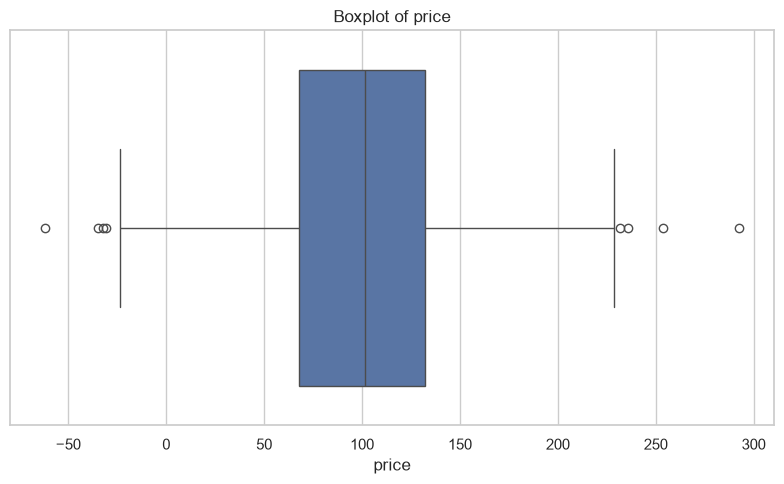

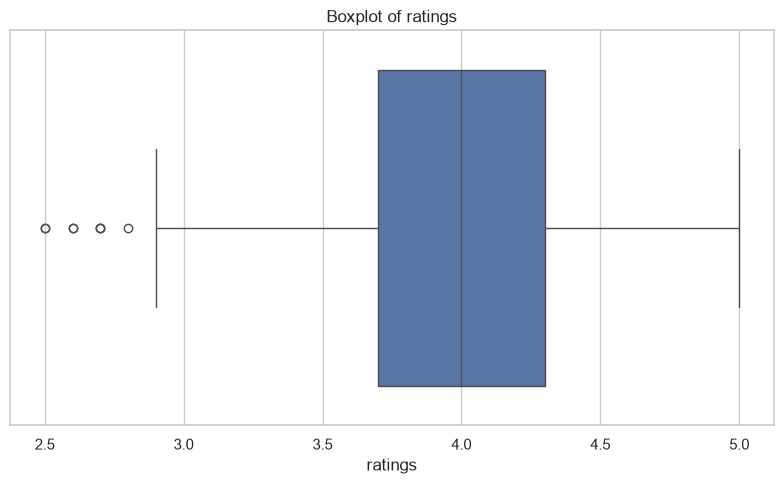

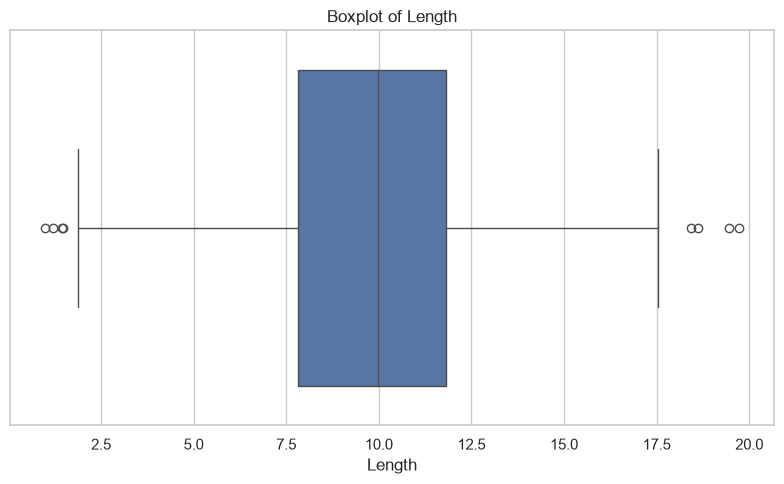

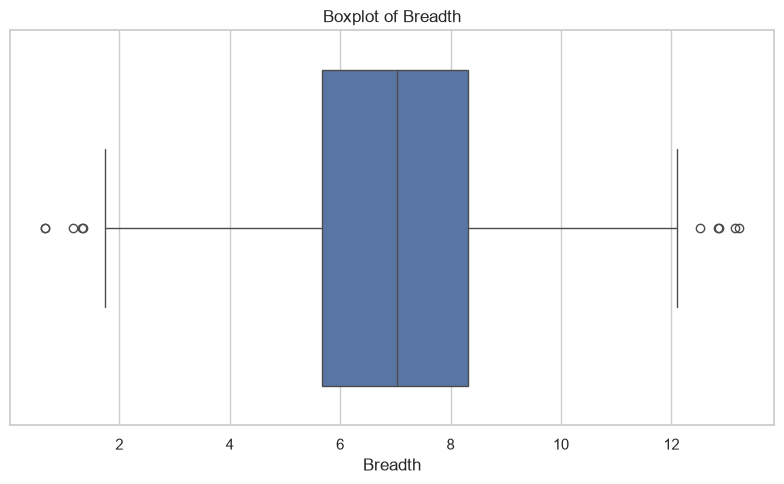

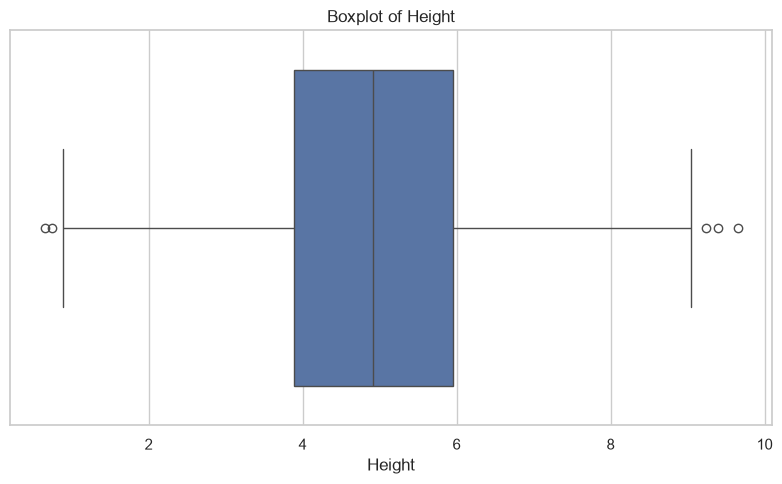

In [56]:
for col in numeric_cols:
    plt.figure(figsize=(8, 5))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)
    plt.tight_layout()
    plt.show()


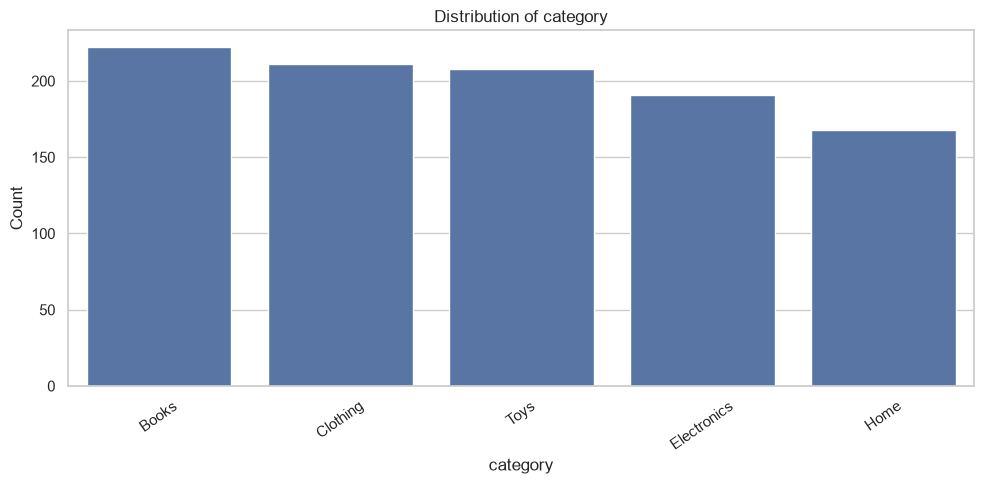

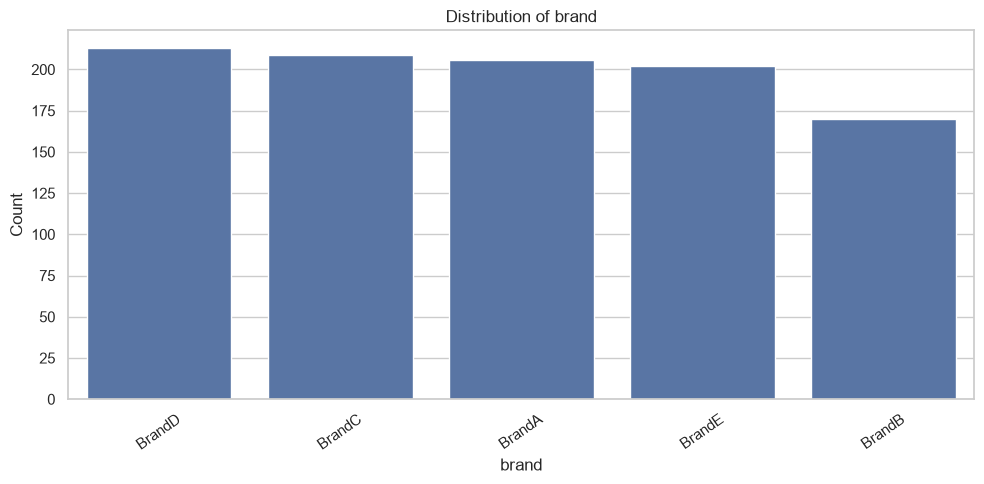

In [57]:
for col in categorical_cols:
    if df[col].nunique(dropna=False) <= 20:
        plt.figure(figsize=(10, 5))
        sns.countplot(data=df, x=col, order=df[col].value_counts(dropna=False).index.astype(str))
        plt.title(f"Distribution of {col}")
        plt.xlabel(col)
        plt.ylabel("Count")
        plt.xticks(rotation=35)
        plt.tight_layout()
        plt.show()


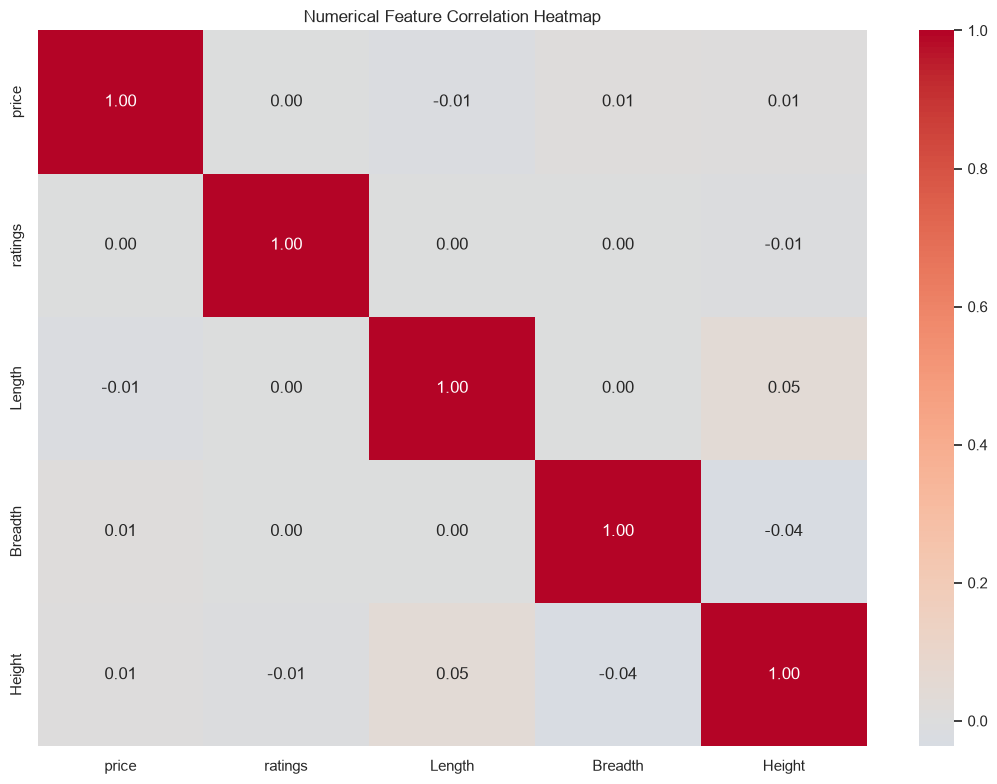

In [58]:
if len(numeric_cols) >= 2:
    plt.figure(figsize=(11, 8))
    sns.heatmap(df[numeric_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
    plt.title("Numerical Feature Correlation Heatmap")
    plt.tight_layout()
    plt.show()


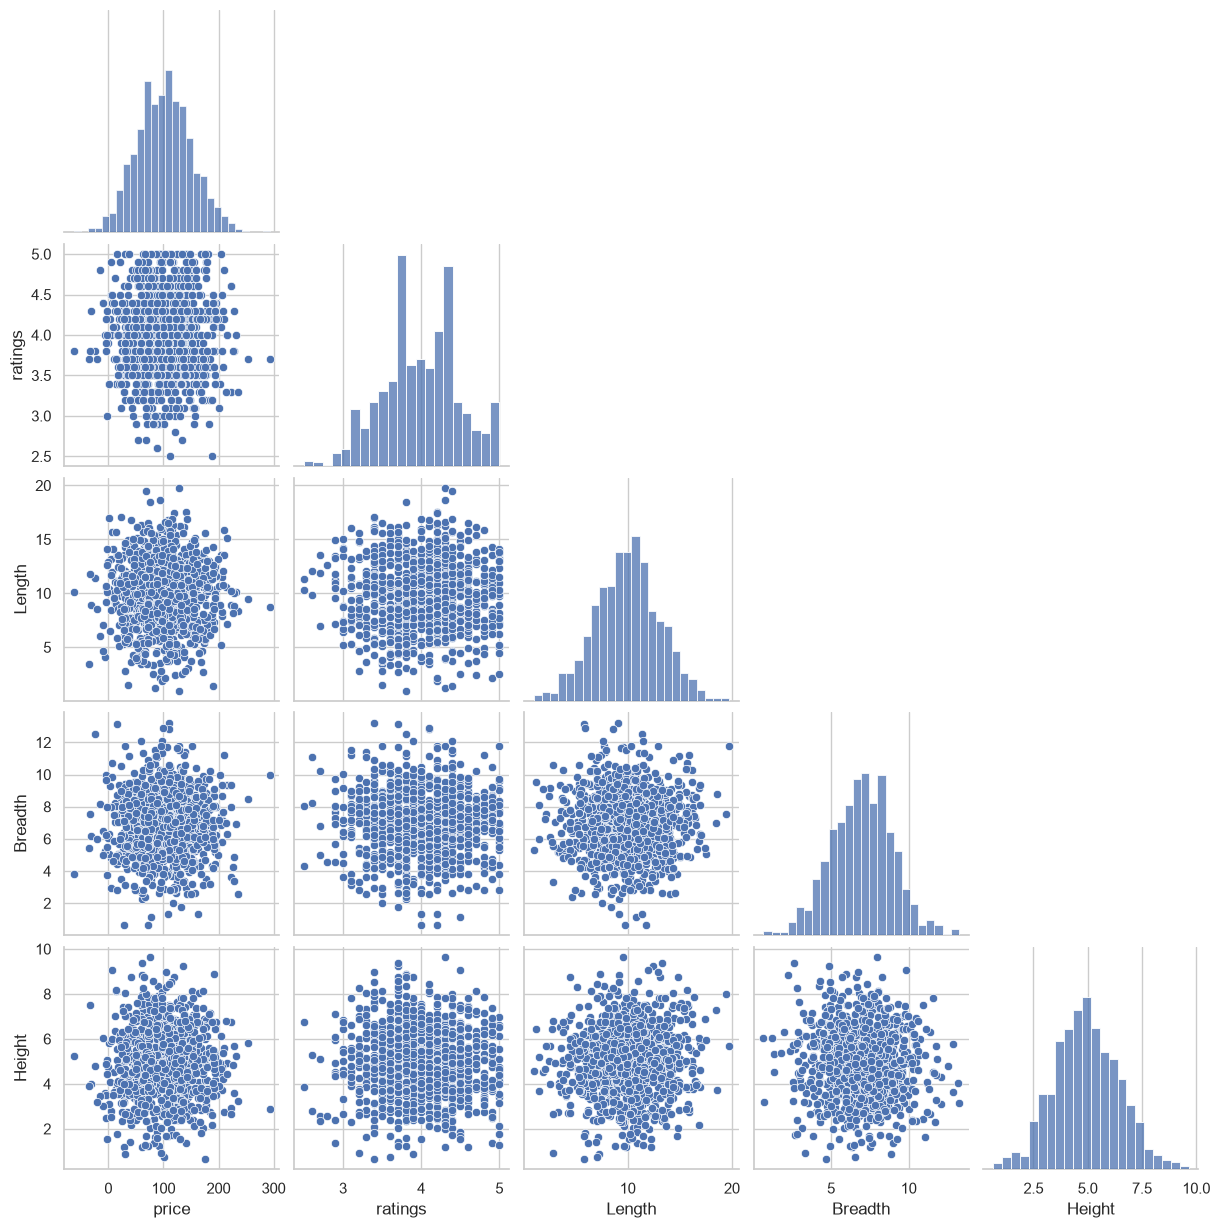

In [59]:
if 2 <= len(numeric_cols) <= 8:
    sns.pairplot(df[numeric_cols], corner=True)
    plt.show()
elif len(numeric_cols) > 8:
    sns.pairplot(df[numeric_cols[:8]], corner=True)
    plt.show()


In [60]:
X_raw = df.copy()

numeric_features = X_raw.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_raw.select_dtypes(exclude=np.number).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

transformers = [("numeric", numeric_pipeline, numeric_features)]

if categorical_features:
    try:
        encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", encoder)
    ])
    transformers.append(("categorical", categorical_pipeline, categorical_features))

preprocessor = ColumnTransformer(transformers=transformers, remainder="drop")
X_processed = preprocessor.fit_transform(X_raw)
X_processed = np.asarray(X_processed, dtype=float)

feature_names = []
feature_names.extend(numeric_features)

if categorical_features:
    fitted_encoder = preprocessor.named_transformers_["categorical"].named_steps["encoder"]
    feature_names.extend(fitted_encoder.get_feature_names_out(categorical_features).tolist())

print("Processed matrix shape:", X_processed.shape)
print("Number of processed features:", len(feature_names))


Processed matrix shape: (1000, 15)
Number of processed features: 15


Explained variance ratio: [0.16147672 0.15306253]
Total explained variance: 0.31453925302319063


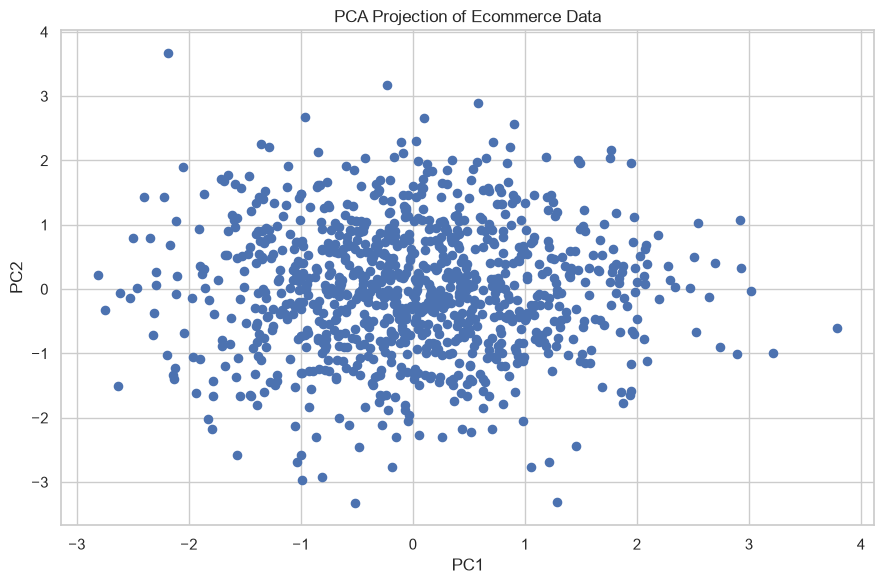

In [61]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_processed)

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total explained variance:", pca.explained_variance_ratio_.sum())

plt.figure(figsize=(9, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], s=35)
plt.title("PCA Projection of Ecommerce Data")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.tight_layout()
plt.show()


In [62]:
k_values = range(2, 11)
kmeans_results = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = model.fit_predict(X_processed)
    kmeans_results.append({
        "K": k,
        "Inertia": model.inertia_,
        "Silhouette Score": silhouette_score(X_processed, labels),
        "Calinski-Harabasz Score": calinski_harabasz_score(X_processed, labels),
        "Davies-Bouldin Score": davies_bouldin_score(X_processed, labels)
    })

kmeans_metrics = pd.DataFrame(kmeans_results)
display(kmeans_metrics)


,K,Inertia,Silhouette Score,Calinski-Harabasz Score,Davies-Bouldin Score
0,2,5919.551137,0.095348,114.219791,2.882626
1,3,5432.596965,0.092855,106.849977,2.455181
2,4,5070.133376,0.093015,99.983893,2.230071
3,5,4762.705856,0.094565,95.804704,2.062959
4,6,4507.277524,0.098151,92.171823,1.934109
5,7,4346.803168,0.095090,85.675270,1.936604
6,8,4221.838644,0.095038,79.728153,1.951135
7,9,4086.093042,0.093857,76.122363,1.907862
8,10,3974.372594,0.093703,72.588306,1.912824


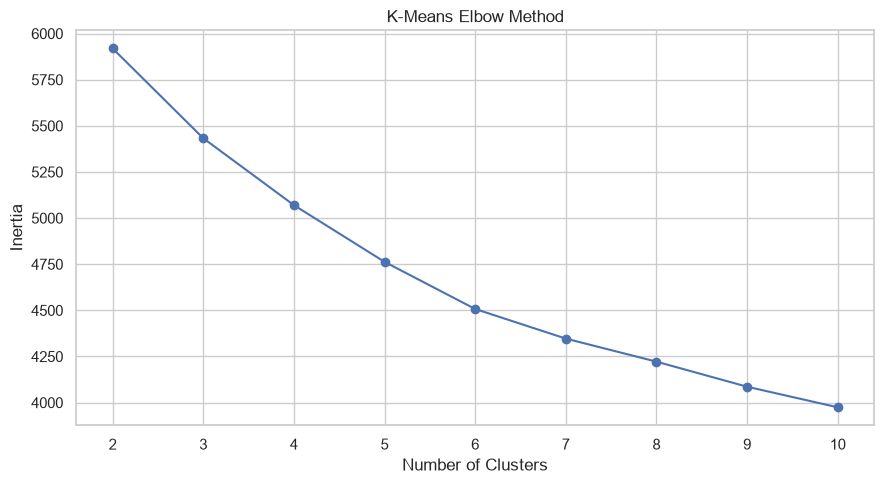

In [63]:
plt.figure(figsize=(9, 5))
plt.plot(kmeans_metrics["K"], kmeans_metrics["Inertia"], marker="o")
plt.title("K-Means Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.tight_layout()
plt.show()


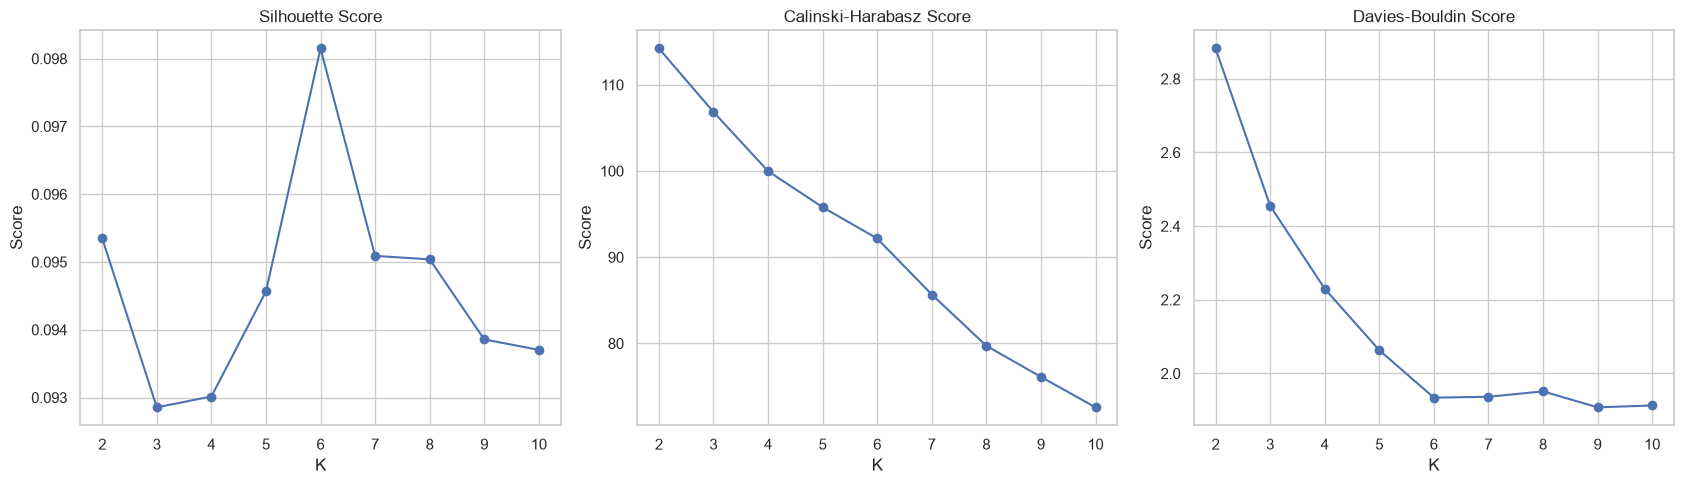

In [64]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
axes[0].plot(kmeans_metrics["K"], kmeans_metrics["Silhouette Score"], marker="o")
axes[0].set_title("Silhouette Score")
axes[0].set_xlabel("K")
axes[0].set_ylabel("Score")
axes[1].plot(kmeans_metrics["K"], kmeans_metrics["Calinski-Harabasz Score"], marker="o")
axes[1].set_title("Calinski-Harabasz Score")
axes[1].set_xlabel("K")
axes[1].set_ylabel("Score")
axes[2].plot(kmeans_metrics["K"], kmeans_metrics["Davies-Bouldin Score"], marker="o")
axes[2].set_title("Davies-Bouldin Score")
axes[2].set_xlabel("K")
axes[2].set_ylabel("Score")
plt.tight_layout()
plt.show()


In [65]:
kmeans_k = int(kmeans_metrics.loc[kmeans_metrics["Silhouette Score"].idxmax(), "K"])
kmeans_model = KMeans(n_clusters=kmeans_k, random_state=42, n_init=20)
kmeans_labels = kmeans_model.fit_predict(X_processed)

df_kmeans = df.copy()
df_kmeans["KMeans_Cluster"] = kmeans_labels

print("Selected K:", kmeans_k)
display(df_kmeans["KMeans_Cluster"].value_counts().sort_index().to_frame("Count"))


Selected K: 6


,Count
KMeans_Cluster,
0,183
1,174
2,179
3,160
4,159
5,145


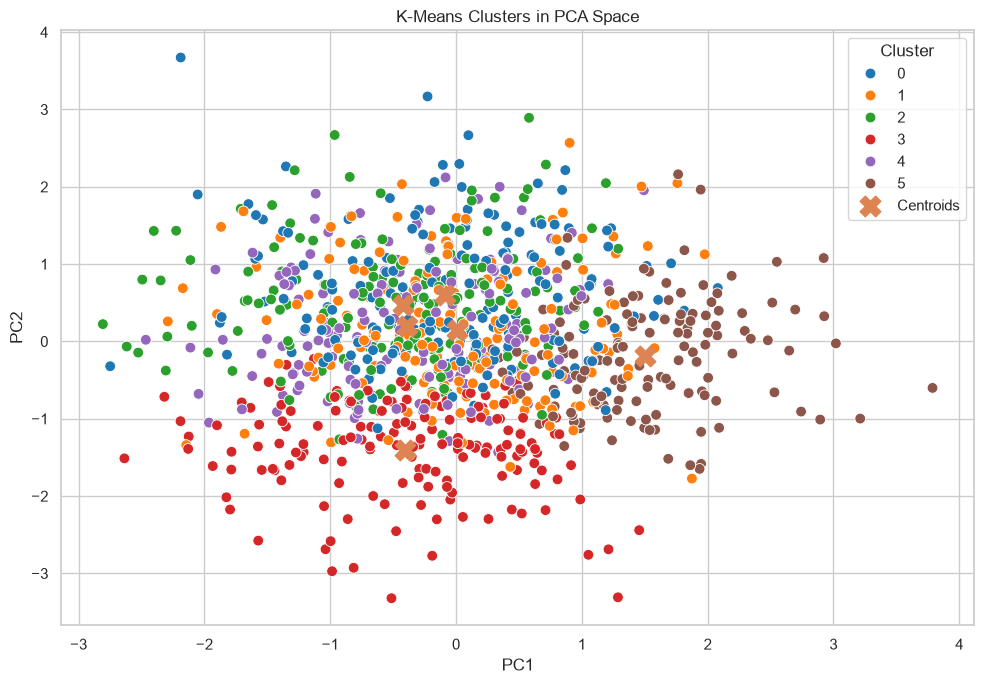

In [66]:
plt.figure(figsize=(10, 7))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=kmeans_labels, palette="tab10", s=60)
centers_pca = pca.transform(kmeans_model.cluster_centers_)
plt.scatter(centers_pca[:, 0], centers_pca[:, 1], marker="X", s=220, label="Centroids")
plt.title("K-Means Clusters in PCA Space")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()


In [67]:
kmeans_final_metrics = pd.DataFrame([{
    "Model": "K-Means",
    "Clusters": kmeans_k,
    "Silhouette Score": silhouette_score(X_processed, kmeans_labels),
    "Calinski-Harabasz Score": calinski_harabasz_score(X_processed, kmeans_labels),
    "Davies-Bouldin Score": davies_bouldin_score(X_processed, kmeans_labels)
}])
display(kmeans_final_metrics)

if numeric_features:
    display(df_kmeans.groupby("KMeans_Cluster")[numeric_features].mean().round(3))


,Model,Clusters,Silhouette Score,Calinski-Harabasz Score,Davies-Bouldin Score
0,K-Means,6,0.098151,92.171823,1.934109


,price,ratings,Length,Breadth,Height
KMeans_Cluster,,,,,
0,143.255,4.295,12.231,7.099,4.262
1,127.219,3.612,8.471,5.193,4.602
2,92.280,3.567,10.300,9.032,4.658
3,45.971,4.186,9.264,6.204,3.774
4,112.632,4.382,7.159,7.903,5.763
5,74.709,3.946,12.143,6.199,6.809


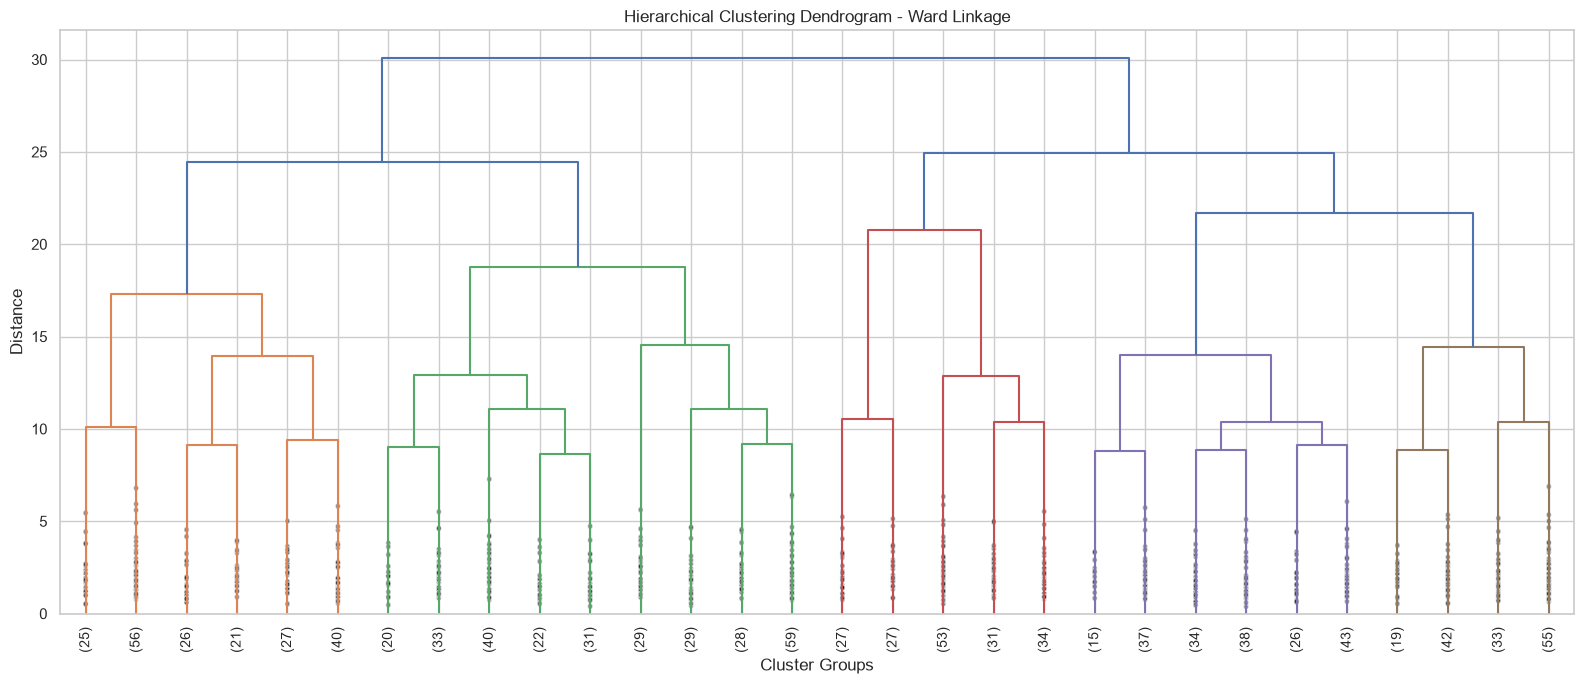

In [68]:
from scipy.cluster.hierarchy import linkage, dendrogram

linkage_matrix = linkage(X_processed, method="ward")

plt.figure(figsize=(16, 7))
dendrogram(
    linkage_matrix,
    truncate_mode="lastp",
    p=30,
    leaf_rotation=90,
    leaf_font_size=10,
    show_contracted=True
)
plt.title("Hierarchical Clustering Dendrogram - Ward Linkage")
plt.xlabel("Cluster Groups")
plt.ylabel("Distance")
plt.tight_layout()
plt.show()


In [69]:
hier_results = []

for k in k_values:
    model = AgglomerativeClustering(n_clusters=k, linkage="ward")
    labels = model.fit_predict(X_processed)
    hier_results.append({
        "K": k,
        "Silhouette Score": silhouette_score(X_processed, labels),
        "Calinski-Harabasz Score": calinski_harabasz_score(X_processed, labels),
        "Davies-Bouldin Score": davies_bouldin_score(X_processed, labels)
    })

hier_metrics = pd.DataFrame(hier_results)
display(hier_metrics)


,K,Silhouette Score,Calinski-Harabasz Score,Davies-Bouldin Score
0,2,0.065076,73.418727,3.586647
1,3,0.052725,65.224084,3.120525
2,4,0.047847,63.700466,2.840777
3,5,0.039208,60.888681,2.675045
4,6,0.041009,59.188062,2.486061
5,7,0.040602,57.002618,2.493863
6,8,0.041013,54.809982,2.454229
7,9,0.041757,51.811843,2.336955
8,10,0.038654,49.577931,2.301093


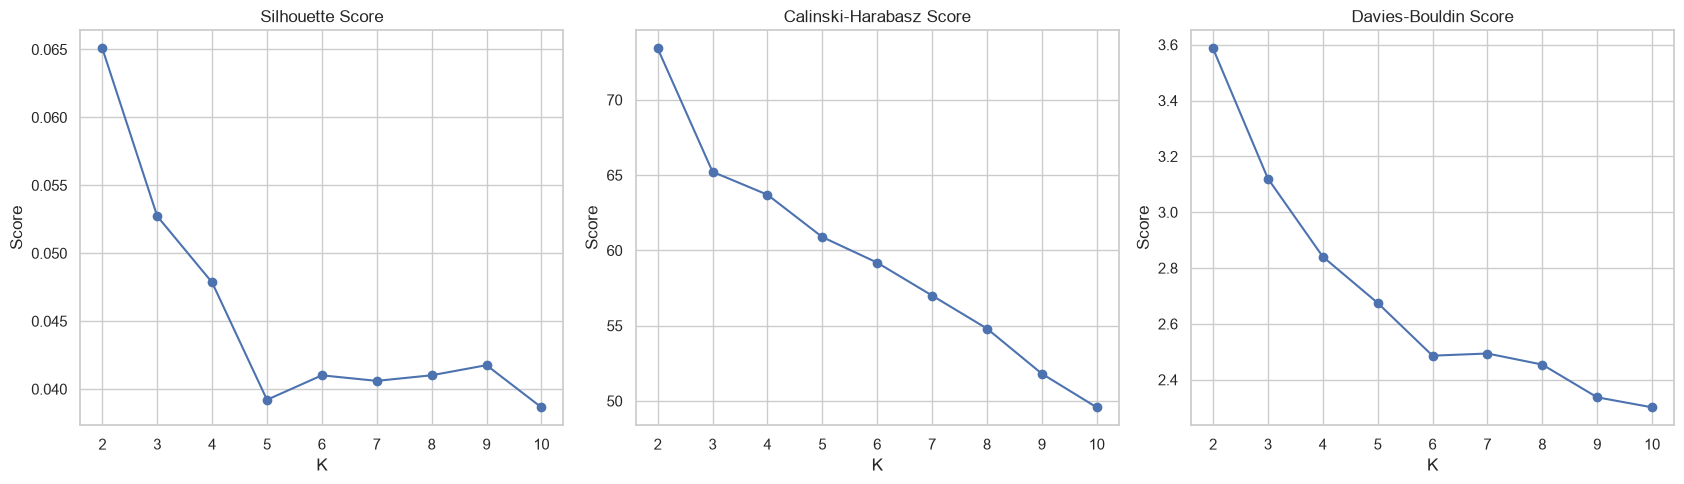

In [70]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
axes[0].plot(hier_metrics["K"], hier_metrics["Silhouette Score"], marker="o")
axes[0].set_title("Silhouette Score")
axes[0].set_xlabel("K")
axes[0].set_ylabel("Score")
axes[1].plot(hier_metrics["K"], hier_metrics["Calinski-Harabasz Score"], marker="o")
axes[1].set_title("Calinski-Harabasz Score")
axes[1].set_xlabel("K")
axes[1].set_ylabel("Score")
axes[2].plot(hier_metrics["K"], hier_metrics["Davies-Bouldin Score"], marker="o")
axes[2].set_title("Davies-Bouldin Score")
axes[2].set_xlabel("K")
axes[2].set_ylabel("Score")
plt.tight_layout()
plt.show()


In [71]:
hier_k = int(hier_metrics.loc[hier_metrics["Silhouette Score"].idxmax(), "K"])
hier_model = AgglomerativeClustering(n_clusters=hier_k, linkage="ward")
hier_labels = hier_model.fit_predict(X_processed)

df_hier = df.copy()
df_hier["Hierarchical_Cluster"] = hier_labels

print("Selected K:", hier_k)
display(df_hier["Hierarchical_Cluster"].value_counts().sort_index().to_frame("Count"))


Selected K: 2


,Count
Hierarchical_Cluster,
0,514
1,486


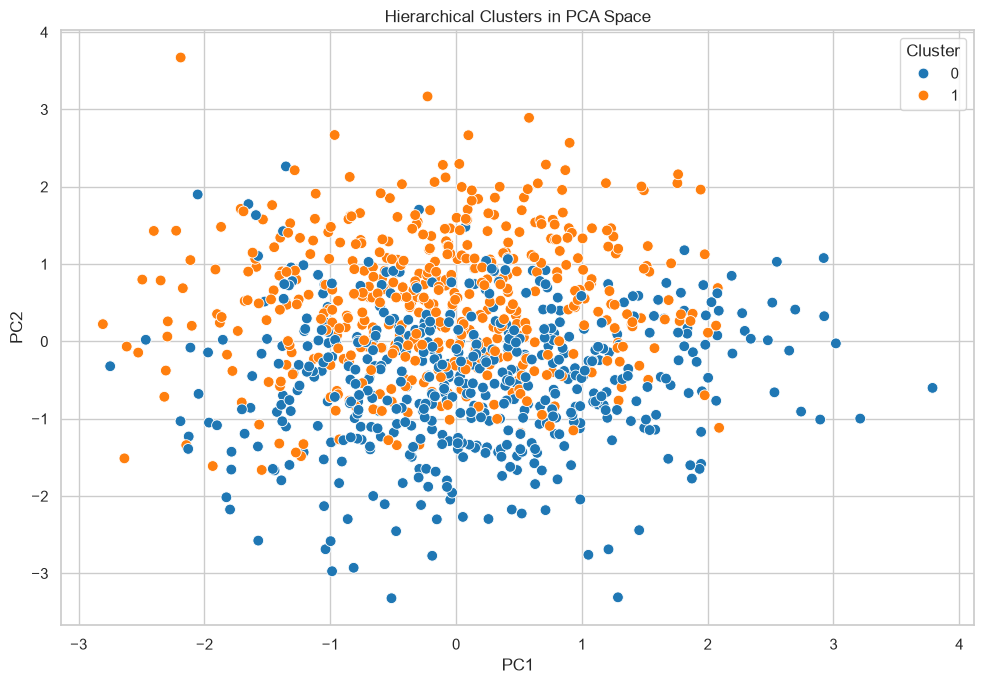

In [72]:
plt.figure(figsize=(10, 7))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=hier_labels, palette="tab10", s=60)
plt.title("Hierarchical Clusters in PCA Space")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()


In [73]:
hier_final_metrics = pd.DataFrame([{
    "Model": "Hierarchical",
    "Clusters": hier_k,
    "Silhouette Score": silhouette_score(X_processed, hier_labels),
    "Calinski-Harabasz Score": calinski_harabasz_score(X_processed, hier_labels),
    "Davies-Bouldin Score": davies_bouldin_score(X_processed, hier_labels)
}])
display(hier_final_metrics)

if numeric_features:
    display(df_hier.groupby("Hierarchical_Cluster")[numeric_features].mean().round(3))


,Model,Clusters,Silhouette Score,Calinski-Harabasz Score,Davies-Bouldin Score
0,Hierarchical,2,0.065076,73.418727,3.586647


,price,ratings,Length,Breadth,Height
Hierarchical_Cluster,,,,,
0,85.799,4.226,9.816,6.368,4.984
1,117.007,3.743,10.066,7.601,4.857


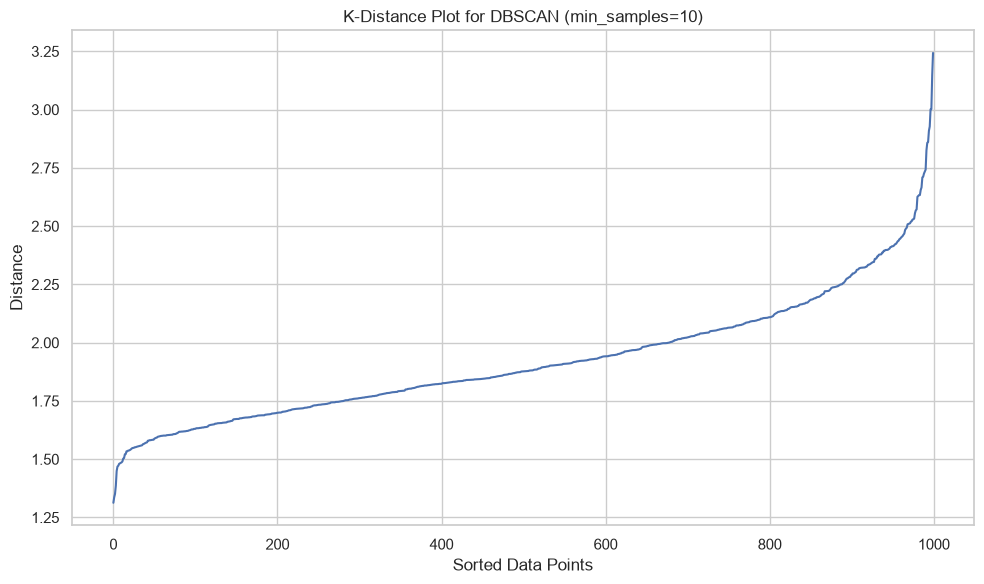

In [74]:
min_samples_for_plot = max(5, min(10, X_processed.shape[1] + 1))
nearest = NearestNeighbors(n_neighbors=min_samples_for_plot)
nearest.fit(X_processed)
distances, _ = nearest.kneighbors(X_processed)
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(10, 6))
plt.plot(k_distances)
plt.title(f"K-Distance Plot for DBSCAN (min_samples={min_samples_for_plot})")
plt.xlabel("Sorted Data Points")
plt.ylabel("Distance")
plt.tight_layout()
plt.show()


In [75]:
eps_values = np.round(np.arange(0.2, 2.01, 0.1), 2)
min_samples_values = [3, 5, 7, 10, 15]

dbscan_results = []

for eps in eps_values:
    for min_samples in min_samples_values:
        model = DBSCAN(eps=float(eps), min_samples=int(min_samples))
        labels = model.fit_predict(X_processed)
        non_noise = labels != -1
        n_clusters = len(set(labels[non_noise]))
        n_noise = int(np.sum(labels == -1))
        if n_clusters >= 2 and np.sum(non_noise) > n_clusters:
            eval_X = X_processed[non_noise]
            eval_labels = labels[non_noise]
            sil = silhouette_score(eval_X, eval_labels)
            ch = calinski_harabasz_score(eval_X, eval_labels)
            db = davies_bouldin_score(eval_X, eval_labels)
        else:
            sil, ch, db = np.nan, np.nan, np.nan
        dbscan_results.append({
            "eps": float(eps),
            "min_samples": int(min_samples),
            "Clusters": n_clusters,
            "Noise Points": n_noise,
            "Silhouette Score": sil,
            "Calinski-Harabasz Score": ch,
            "Davies-Bouldin Score": db
        })

dbscan_metrics = pd.DataFrame(dbscan_results)
display(dbscan_metrics.sort_values("Silhouette Score", ascending=False).head(20))


,eps,min_samples,Clusters,Noise Points,Silhouette Score,Calinski-Harabasz Score,Davies-Bouldin Score
20,0.6,3,2,992,0.731992,45.549972,0.330745
25,0.7,3,4,986,0.701127,44.045699,0.358958
30,0.8,3,7,977,0.635261,35.200970,0.448852
35,0.9,3,13,950,0.510651,24.912868,0.646125
46,1.1,5,6,965,0.474888,23.740089,0.742786
41,1.0,5,2,988,0.459644,13.867329,0.809484
40,1.0,3,16,926,0.419774,16.909467,0.820599
63,1.4,10,3,967,0.386752,23.831699,1.017663
52,1.2,7,3,977,0.381598,16.256364,0.951857
51,1.2,5,7,945,0.363358,17.975080,0.997928


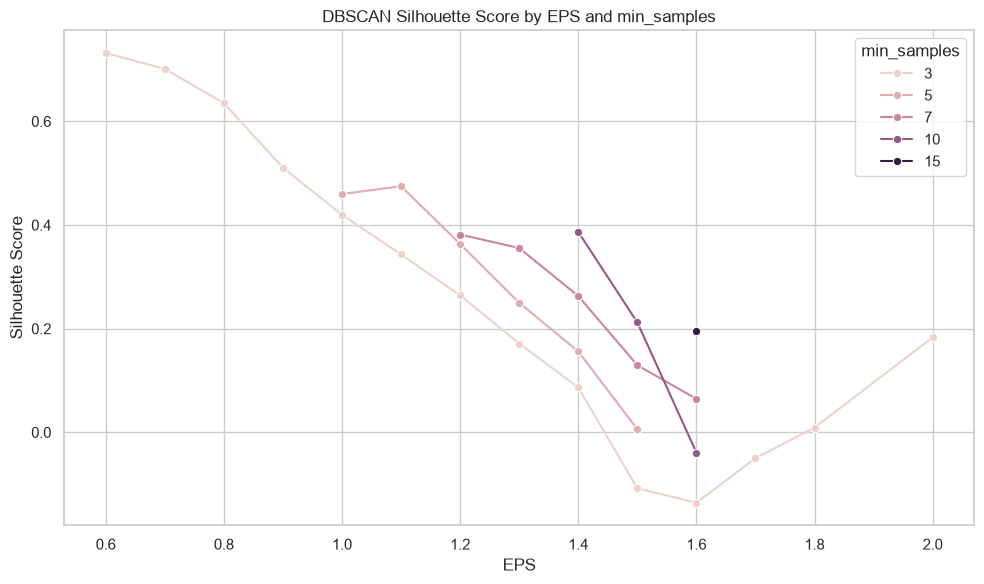

In [76]:
plt.figure(figsize=(10, 6))
sns.lineplot(data=dbscan_metrics, x="eps", y="Silhouette Score", hue="min_samples", marker="o")
plt.title("DBSCAN Silhouette Score by EPS and min_samples")
plt.xlabel("EPS")
plt.ylabel("Silhouette Score")
plt.tight_layout()
plt.show()


In [77]:
valid_dbscan = dbscan_metrics.dropna(subset=["Silhouette Score"])

if valid_dbscan.empty:
    raise ValueError("No DBSCAN parameter combination produced at least two non-noise clusters.")

best_dbscan = valid_dbscan.loc[valid_dbscan["Silhouette Score"].idxmax()]
dbscan_eps = float(best_dbscan["eps"])
dbscan_min_samples = int(best_dbscan["min_samples"])

dbscan_model = DBSCAN(eps=dbscan_eps, min_samples=dbscan_min_samples)
dbscan_labels = dbscan_model.fit_predict(X_processed)

df_dbscan = df.copy()
df_dbscan["DBSCAN_Cluster"] = dbscan_labels

print("Best EPS:", dbscan_eps)
print("Best min_samples:", dbscan_min_samples)
print("Number of clusters excluding noise:", len(set(dbscan_labels) - {-1}))
print("Noise points:", int(np.sum(dbscan_labels == -1)))
display(df_dbscan["DBSCAN_Cluster"].value_counts().sort_index().to_frame("Count"))


Best EPS: 0.6
Best min_samples: 3
Number of clusters excluding noise: 2
Noise points: 992


,Count
DBSCAN_Cluster,
-1,992
0,5
1,3


In [78]:
non_noise = dbscan_labels != -1
n_db_clusters = len(set(dbscan_labels[non_noise]))

if n_db_clusters >= 2:
    dbscan_sil = silhouette_score(X_processed[non_noise], dbscan_labels[non_noise])
    dbscan_ch = calinski_harabasz_score(X_processed[non_noise], dbscan_labels[non_noise])
    dbscan_db = davies_bouldin_score(X_processed[non_noise], dbscan_labels[non_noise])
else:
    dbscan_sil, dbscan_ch, dbscan_db = np.nan, np.nan, np.nan

dbscan_final_metrics = pd.DataFrame([{
    "Model": "DBSCAN",
    "Clusters": n_db_clusters,
    "Noise Points": int(np.sum(dbscan_labels == -1)),
    "Silhouette Score": dbscan_sil,
    "Calinski-Harabasz Score": dbscan_ch,
    "Davies-Bouldin Score": dbscan_db
}])
display(dbscan_final_metrics)

if numeric_features:
    display(df_dbscan.groupby("DBSCAN_Cluster")[numeric_features].mean().round(3))


,Model,Clusters,Noise Points,Silhouette Score,Calinski-Harabasz Score,Davies-Bouldin Score
0,DBSCAN,2,992,0.731992,45.549972,0.330745


,price,ratings,Length,Breadth,Height
DBSCAN_Cluster,,,,,
-1,100.788,3.993,9.932,6.953,4.923
0,128.634,4.020,11.730,8.808,4.446
1,113.883,3.633,8.820,8.533,5.427


,K-Means,Hierarchical,DBSCAN
-1,0.0,0.0,992.0
0,183.0,514.0,5.0
1,174.0,486.0,3.0
2,179.0,0.0,0.0
3,160.0,0.0,0.0
4,159.0,0.0,0.0
5,145.0,0.0,0.0


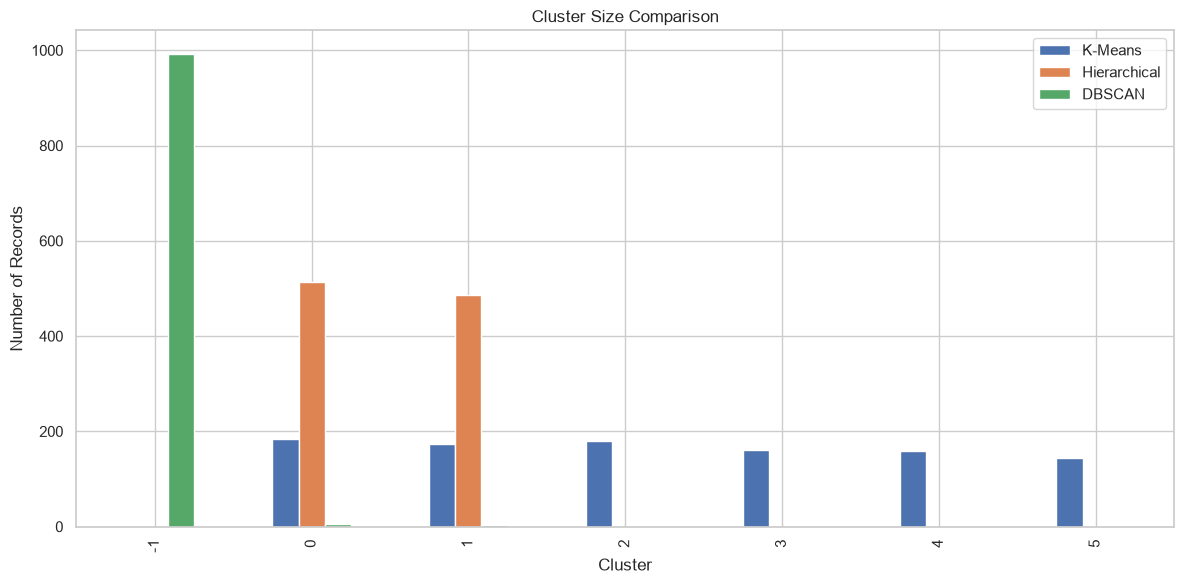

In [82]:
cluster_sizes = pd.DataFrame({
    "K-Means": df_kmeans["KMeans_Cluster"].value_counts().sort_index(),
    "Hierarchical": df_hier["Hierarchical_Cluster"].value_counts().sort_index(),
    "DBSCAN": df_dbscan["DBSCAN_Cluster"].value_counts().sort_index()
}).fillna(0)

display(cluster_sizes)

cluster_sizes.plot(kind="bar", figsize=(12, 6))
plt.title("Cluster Size Comparison")
plt.xlabel("Cluster")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()


In [83]:
model_comparison = pd.concat([
    kmeans_final_metrics,
    hier_final_metrics,
    dbscan_final_metrics[["Model", "Clusters", "Silhouette Score", "Calinski-Harabasz Score", "Davies-Bouldin Score"]]
], ignore_index=True)

display(model_comparison)


,Model,Clusters,Silhouette Score,Calinski-Harabasz Score,Davies-Bouldin Score
0,K-Means,6,0.098151,92.171823,1.934109
1,Hierarchical,2,0.065076,73.418727,3.586647
2,DBSCAN,2,0.731992,45.549972,0.330745


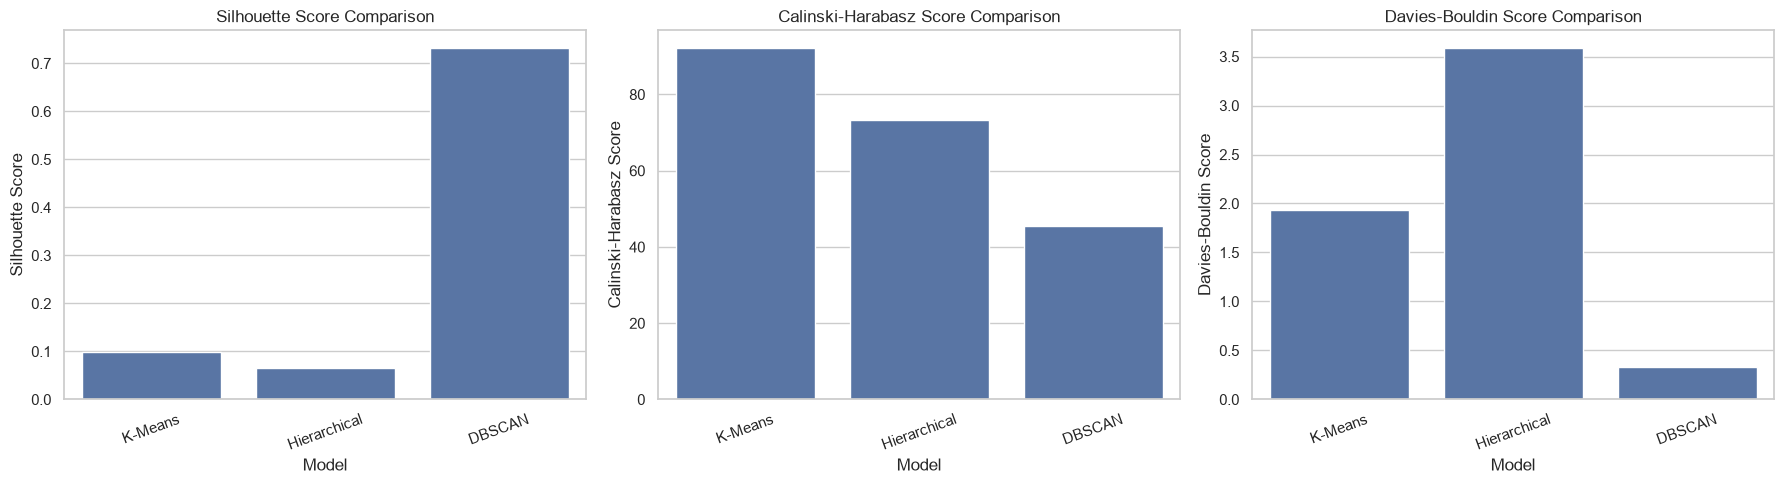

In [84]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.barplot(data=model_comparison, x="Model", y="Silhouette Score", ax=axes[0])
axes[0].set_title("Silhouette Score Comparison")
axes[0].tick_params(axis="x", rotation=20)

sns.barplot(data=model_comparison, x="Model", y="Calinski-Harabasz Score", ax=axes[1])
axes[1].set_title("Calinski-Harabasz Score Comparison")
axes[1].tick_params(axis="x", rotation=20)

sns.barplot(data=model_comparison, x="Model", y="Davies-Bouldin Score", ax=axes[2])
axes[2].set_title("Davies-Bouldin Score Comparison")
axes[2].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()


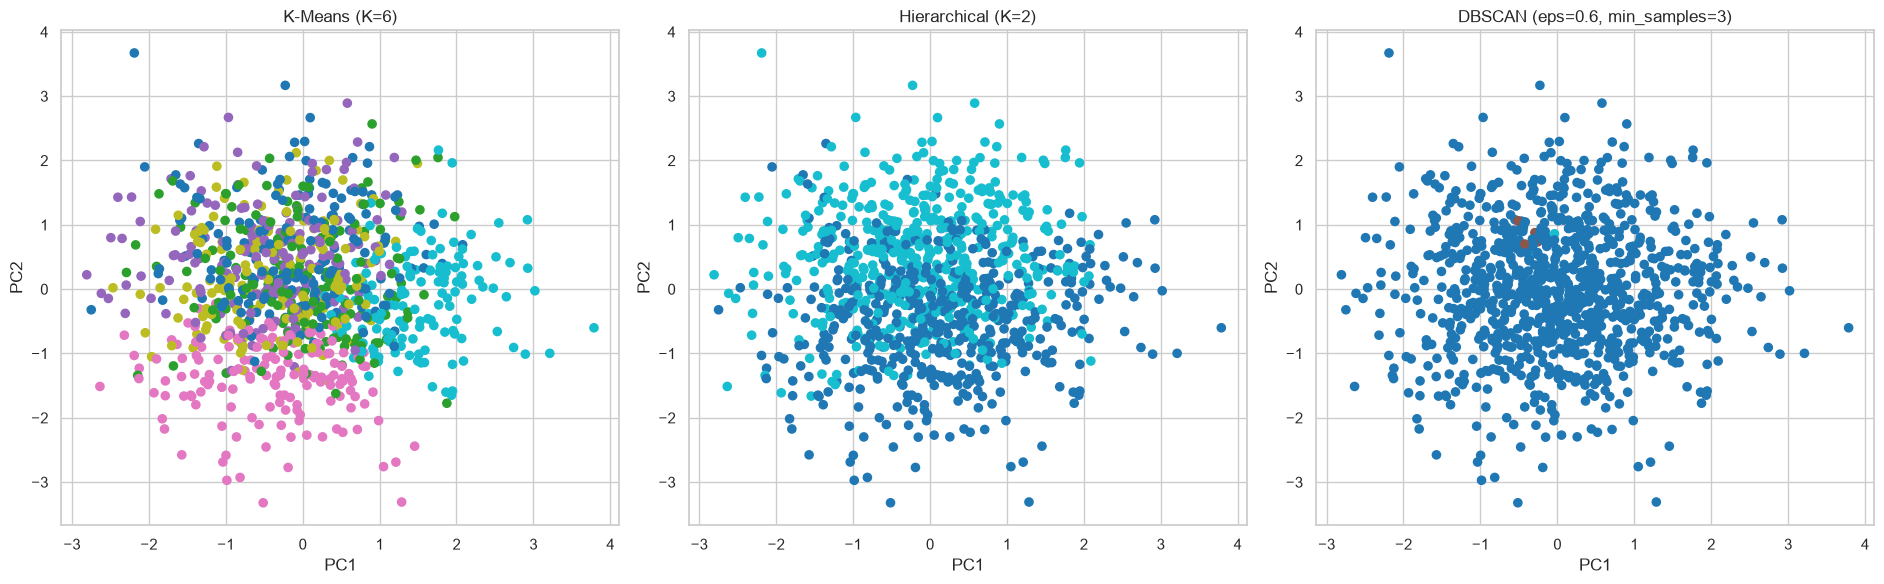

In [85]:
fig, axes = plt.subplots(1, 3, figsize=(19, 6))

axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap="tab10", s=35)
axes[0].set_title(f"K-Means (K={kmeans_k})")
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")

axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=hier_labels, cmap="tab10", s=35)
axes[1].set_title(f"Hierarchical (K={hier_k})")
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")

axes[2].scatter(X_pca[:, 0], X_pca[:, 1], c=dbscan_labels, cmap="tab10", s=35)
axes[2].set_title(f"DBSCAN (eps={dbscan_eps}, min_samples={dbscan_min_samples})")
axes[2].set_xlabel("PC1")
axes[2].set_ylabel("PC2")

plt.tight_layout()
plt.show()
